# Classifying dredge candidates

The USGS detectors sometimes marked the same dredge twice, so a classifier could recognize both spots and still overcount the boats on the river. I started with the 21 features from notebook 02 to score each candidate, then kept the spot with the highest score when several detections fell close together on the same date. For comparison, I also used brightness alone to decide which of two nearby spots to keep. I scored both approaches against the hand labels using precision, recall and F1, as in notebook 01.

A dredge tied to the bank from June 4 to June 16 could easily appear on both sides of a random split. I kept all observations from a site together for testing and assigned each hand label to the site of the nearest candidate within 60m on the same date. The 20 labels with no candidate that close still count in the score for the whole river.

In [1]:
import xml.etree.ElementTree as ET
from itertools import product

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import torch
from skimage.feature import peak_local_max
from skimage.io import imread
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from torch import nn

from helpers import BLUE, ON_DREDGE, ORANGE, OUT, PROC, RAW, UTM, chip, db, load_points, prf, scene, score

SEED = 27
cands = gpd.read_file(PROC / "candidates.gpkg").to_crs(UTM)
cands["date"] = pd.to_datetime(cands["date"])
features = [c for c in cands.columns if c not in ("date", "source", "dredge", "site", "geometry")]
labels = load_points("Visual")


def label_site(date, point):
    # the site of the nearest candidate on the same date, or -1 if none is within 60m
    dist = cands[cands["date"] == date].distance(point)
    return cands.at[dist.idxmin(), "site"] if len(dist) and dist.min() <= ON_DREDGE else -1


def truth(part):
    # the labeled dredges at the sites in part
    return labels[labels["site"].isin(part["site"])]


labels["site"] = [label_site(d, p) for d, p in zip(labels["date"], labels.geometry)]
# the two big dredge fields (over 20 candidates) always stay in training; a third of the other sites becomes the test set
pool = cands[cands["site"].map(cands["site"].value_counts()) <= 20]
_, test_pos = next(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED).split(pool, pool["dredge"], groups=pool["site"]))
test = pool.iloc[test_pos]
train = cands.drop(test.index)

pd.DataFrame({name: {"candidates": len(df), "sites": df["site"].nunique(), "false alarms": (df["dredge"] == 0).sum(),
                     "false alarm share": round(1 - df["dredge"].mean(), 2), "largest site": df["site"].value_counts().max(),
                     "labeled dredges": len(truth(df))} for name, df in [("train", train), ("test", test)]}).T

,candidates,sites,false alarms,false alarm share,largest site,labeled dredges
train,225.0,75.0,28.0,0.12,49.0,143.0
test,67.0,34.0,13.0,0.19,14.0,41.0


I kept the two largest dredge fields in training and held out 34 of the remaining sites. Those two fields had few false alarms, which helps explain why false alarms made up 19% of the test candidates and 12% of the training candidates.

Starting with the best score on each date, `detect` keeps candidates that meet the cutoff and fall outside the merge distance of a spot it already kept. I used `score` from `helpers.py` to match the remaining detections to hand labels within 30m.

Some neighboring dredges sat only 30 to 40m apart. I tried several merge distances on the training sites to see where I started losing separate boats, using all candidates and the Local detections alone as my two baselines.

In [2]:
def detect(df, scores, cutoff, radius):
    """drop candidates below the cutoff, then on each date keep the best-scoring candidate within `radius` meters."""
    kept = []
    for _, g in df.assign(s=scores).groupby("date"):
        g = g[g["s"] >= cutoff].sort_values("s", ascending=False)
        xy, chosen = np.c_[g.geometry.x, g.geometry.y], []
        for k in range(len(g)):
            if all(np.hypot(*(xy[k] - xy[j])) > radius for j in chosen):
                chosen.append(k)
        kept.append(g.iloc[chosen])
    return pd.concat(kept)


baselines = {"Keep every candidate": score(train, truth(train)),
             "Keep the Local method's candidates": score(train[train["source"] != "Global only"], truth(train))}
for radius in [20, 30, 35, 40, 50, 60]:
    # no model yet: brightness just decides which of two near-duplicates to keep
    baselines[f"Keep every candidate, merge within {radius}m"] = score(detect(train, train["vv_peak"].values, -np.inf, radius), truth(train))
pd.DataFrame(baselines).T.round(2)

,TP,FP,FN,precision,recall,F1
Keep every candidate,138.0,87.0,5.0,0.61,0.97,0.75
Keep the Local method's candidates,120.0,69.0,23.0,0.63,0.84,0.72
"Keep every candidate, merge within 20m",138.0,79.0,5.0,0.64,0.97,0.77
"Keep every candidate, merge within 30m",134.0,54.0,9.0,0.71,0.94,0.81
"Keep every candidate, merge within 35m",131.0,44.0,12.0,0.75,0.92,0.82
"Keep every candidate, merge within 40m",127.0,42.0,16.0,0.75,0.89,0.81
"Keep every candidate, merge within 50m",119.0,38.0,24.0,0.76,0.83,0.79
"Keep every candidate, merge within 60m",117.0,32.0,26.0,0.79,0.82,0.80


Merging nearby detections within 35m cut the number of false positives on the training sites from 87 to 44. I lost a few dredges in the process, bringing recall from 0.97 to 0.92, but F1 rose from 0.75 to 0.82. At wider distances I started losing more neighboring boats, so I kept 35m for the first model comparison. The Local detector alone scored 0.72.

All nine classifiers in the table used the same 21 measurements. They ranged from logistic regression to a small neural network with 16 units in its hidden layer. I included naive Bayes partly out of curiosity about how it would handle the closely related features I saw in notebook 02.

For cross validation I divided the training sites into five groups and took turns leaving one group out. Before fitting a classifier, I filled gaps in contrast with land using the median from the training sites and scaled the features on those same sites if the model needed it. Each classifier’s predictions went through the same 0.5 cutoff and 35m merge before I calculated precision, recall and F1. For the precision and recall curve I treated false alarms as the positive class because they were the rare ones.

In [3]:
MERGE = 35
X_train, y_train = train[features].astype(float), train["dredge"].values
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train, groups=train["site"].values))
COLS = ["precision", "recall", "F1", "F1 fold spread", "ROC AUC", "PR AUC (false alarms)"]


def pipeline(model, scale=False):
    # median fill for contrast_land (missing when there's no land in view), plus a flag for it the model can use
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), *([StandardScaler()] if scale else []), model)


def out_of_fold(model, cols=features):
    """each training candidate's score from a model that never saw its fold."""
    prob = np.zeros(len(train))
    for fit_idx, score_idx in folds:
        prob[score_idx] = model.fit(X_train.iloc[fit_idx][cols], y_train[fit_idx]).predict_proba(X_train.iloc[score_idx][cols])[:, 1]
    return prob


def evaluate(prob, cutoff=0.5, radius=MERGE):
    """end-to-end scores pooled over the folds (each against its own labels), each fold's f1, and the ranking aucs."""
    per_fold = pd.DataFrame([score(detect(train.iloc[i], prob[i], cutoff, radius), truth(train.iloc[i])) for _, i in folds])
    out = prf(*per_fold[["TP", "FP", "FN"]].sum())
    out.update({"F1 fold spread": per_fold["F1"].std(), "ROC AUC": roc_auc_score(y_train, prob),
                # false alarms are the rare class, so pr auc is computed for them
                "PR AUC (false alarms)": average_precision_score(1 - y_train, 1 - prob)})
    return out | {f"F1 fold {k}": f for k, f in enumerate(per_fold["F1"])}


def show(names, cols=COLS):
    return pd.DataFrame(results).T.loc[names, cols].astype(float).round(2)


models = {
    "Logistic regression": pipeline(LogisticRegression(max_iter=2000), scale=True),
    "k-NN (k = 15)": pipeline(KNeighborsClassifier(n_neighbors=15), scale=True),
    "Decision tree": pipeline(DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED)),
    "Random forest": pipeline(RandomForestClassifier(n_estimators=500, min_samples_leaf=2, random_state=SEED, n_jobs=-1)),
    "Extra trees": pipeline(ExtraTreesClassifier(n_estimators=500, min_samples_leaf=2, random_state=SEED, n_jobs=-1)),
    "Gradient boosting": pipeline(HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, random_state=SEED)),
    # the svm has no probabilities of its own; calibration turns its scores into them
    "SVM (RBF kernel)": pipeline(CalibratedClassifierCV(SVC(), ensemble=False), scale=True),
    "Naive Bayes": pipeline(GaussianNB(), scale=True),
    # a weight penalty guards against overfitting 225 rows
    "Neural network (16 units)": pipeline(MLPClassifier(hidden_layer_sizes=(16,), alpha=1e-2, max_iter=3000, random_state=SEED), scale=True),
}
# the merge-only baseline, scored the same way; brightness stands in for a model score
oof = {"Merge only (no model)": train["vv_peak"].values}
results = {"Merge only (no model)": evaluate(oof["Merge only (no model)"], cutoff=-np.inf) | {"ROC AUC": np.nan, "PR AUC (false alarms)": np.nan}}
for name, model in models.items():
    oof[name] = out_of_fold(model)
    results[name] = evaluate(oof[name])
show(list(results)).sort_values("F1", ascending=False)

,precision,recall,F1,F1 fold spread,ROC AUC,PR AUC (false alarms)
Logistic regression,0.85,0.86,0.85,0.12,0.93,0.62
Random forest,0.82,0.83,0.83,0.14,0.89,0.52
Extra trees,0.79,0.85,0.82,0.16,0.89,0.47
Neural network (16 units),0.81,0.84,0.82,0.15,0.92,0.52
Merge only (no model),0.72,0.90,0.80,0.04,NaN,NaN
Decision tree,0.77,0.83,0.80,0.10,0.81,0.36
Gradient boosting,0.78,0.83,0.80,0.13,0.91,0.62
Naive Bayes,0.86,0.75,0.80,0.21,0.86,0.33
k-NN (k = 15),0.70,0.89,0.78,0.07,0.89,0.43
SVM (RBF kernel),0.74,0.77,0.76,0.29,0.82,0.31


Logistic regression raised precision from 0.72 to 0.85 while recall fell from 0.90 to 0.86. That put its F1 at 0.85 against 0.80 for merging alone on the same folds. Merging scored 0.82 in the earlier table because I scored all the training sites together there.

The single tree roughly tied merging, while the nearest neighbors classifier came in below it at 0.78. The random forest, extra trees and small neural network all finished between 0.82 and 0.83. With the best scores that close together, I wanted to see whether the same models held up across the five folds.

In [4]:
info = []
for _, idx in folds:
    sites = train.iloc[idx]["site"].value_counts()
    info.append({"candidates": len(idx), "false alarms": (y_train[idx] == 0).sum(), "labeled dredges": len(truth(train.iloc[idx])),
                 "largest site": f"site {sites.index[0]} ({sites.iloc[0]})"})
display(pd.DataFrame(info).rename_axis("fold"))
show(list(results), [f"F1 fold {k}" for k in range(5)])

,candidates,false alarms,labeled dredges,largest site
fold,,,,
0,48,5,28,site 9 (43)
1,42,6,30,site 20 (13)
2,53,5,31,site 0 (49)
3,41,6,28,site 57 (7)
4,41,6,26,site 35 (6)


,F1 fold 0,F1 fold 1,F1 fold 2,F1 fold 3,F1 fold 4
Merge only (no model),0.80,0.81,0.73,0.83,0.82
Logistic regression,0.83,0.89,0.65,0.98,0.91
k-NN (k = 15),0.82,0.81,0.66,0.83,0.82
Decision tree,0.86,0.83,0.62,0.87,0.84
Random forest,0.83,0.86,0.57,0.93,0.89
Extra trees,0.84,0.85,0.54,0.95,0.89
Gradient boosting,0.83,0.83,0.59,0.89,0.89
SVM (RBF kernel),0.82,0.83,0.21,0.83,0.90
Naive Bayes,0.83,0.86,0.42,0.94,0.86
Neural network (16 units),0.79,0.89,0.57,0.95,0.91


Of the 53 candidates in fold 2, 49 came from site 0, where a group of dredges stayed tied up along the bank. Only one of those candidates was labeled a false alarm. These boats showed up bright on every date, much like the rocks and patches of shoreline I was trying to filter out. Logistic regression recovered 55% of the labeled dredges in this fold, well below the 77% I got from just merging nearby detections. On the other four folds its F1 ranged from 0.83 to 0.98.

The top models differed by only a few hundredths in F1. Their scores varied much more from fold to fold (standard deviations of 0.12 to 0.16), so I wouldn’t put much weight on their exact order. With only 28 false alarms in training, even a fairly flexible model has few examples of the mistakes it’s supposed to catch.

For logistic regression, random forest and gradient boosting, I tried tuning the model settings along with the score cutoff (0.3 to 0.8) and merge distance (30 to 50m). I chose settings using four inner folds from the training portion of each split, then scored that choice once on the outer fold I’d set aside.

In [5]:
CUTOFFS, RADII = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8], [30, 35, 40, 50]


def pooled_f1(df, prob, parts, cutoff, radius):
    """end-to-end f1 pooled over several parts of df, each scored against its own labels."""
    s = pd.DataFrame([score(detect(df.iloc[i], prob[i], cutoff, radius), truth(df.iloc[i])) for i in parts]).sum()
    return 2 * s["TP"] / (2 * s["TP"] + s["FP"] + s["FN"])


def nested(make_model, grid):
    """settings picked on inner folds only, then scored once on each outer fold."""
    outer, chosen = [], []
    for fit_idx, score_idx in folds:
        inner_df, X_in, y_in = train.iloc[fit_idx], X_train.iloc[fit_idx], y_train[fit_idx]
        inner = list(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED).split(X_in, y_in, groups=inner_df["site"]))
        best = (-1,)
        for params in grid:
            prob = np.zeros(len(fit_idx))
            for a, b in inner:
                prob[b] = make_model(**params).fit(X_in.iloc[a], y_in[a]).predict_proba(X_in.iloc[b])[:, 1]
            # the cutoff and merge only act on the scores, so they're searched without refitting
            for cutoff, radius in product(CUTOFFS, RADII):
                f1 = pooled_f1(inner_df, prob, [b for _, b in inner], cutoff, radius)
                if f1 > best[0]:
                    best = (f1, params, cutoff, radius)
        f1, params, cutoff, radius = best
        prob = make_model(**params).fit(X_in, y_in).predict_proba(X_train.iloc[score_idx])[:, 1]
        outer.append(score(detect(train.iloc[score_idx], prob, cutoff, radius), truth(train.iloc[score_idx])))
        chosen.append({"settings": ", ".join(f"{k} = {v}" for k, v in params.items()), "cutoff": cutoff, "merge (m)": radius, "inner F1": round(f1, 2)})
    outer = pd.DataFrame(outer)
    return prf(*outer[["TP", "FP", "FN"]].sum()) | {"F1 fold spread": outer["F1"].std()}, pd.DataFrame(chosen)


grids = {
    # l1_ratio 1 is l1 (can drop features), 0 is l2 (only shrinks them)
    "Logistic regression": (lambda C, l1_ratio: pipeline(LogisticRegression(C=C, l1_ratio=l1_ratio, solver="liblinear", max_iter=2000), scale=True),
                            [{"C": C, "l1_ratio": r} for C in [0.01, 0.1, 1, 10] for r in [1.0, 0.0]]),
    "Random forest": (lambda leaf, max_features: pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, max_features=max_features, random_state=SEED, n_jobs=-1)),
                      [{"leaf": leaf, "max_features": mf} for leaf in [1, 3, 5] for mf in ["sqrt", 0.5]]),
    "Gradient boosting": (lambda lr, depth: pipeline(HistGradientBoostingClassifier(learning_rate=lr, max_depth=depth, max_iter=200, random_state=SEED)),
                          [{"lr": lr, "depth": d} for lr in [0.03, 0.1] for d in [2, 3]]),
}
tuned = {name: nested(*g) for name, g in grids.items()}
display(pd.DataFrame({n: {"F1, defaults (cutoff 0.5, 35m)": results[n]["F1"], "F1, tuned (nested)": t["F1"], "precision, tuned": t["precision"],
                          "recall, tuned": t["recall"], "F1 fold spread, tuned": t["F1 fold spread"]} for n, (t, _) in tuned.items()}).T.round(2))
# what each outer fold picked; steady picks would mean tuning isn't chasing noise
pd.concat({n: chosen for n, (_, chosen) in tuned.items()}, names=["model", "fold"])

,"F1, defaults (cutoff 0.5, 35m)","F1, tuned (nested)","precision, tuned","recall, tuned","F1 fold spread, tuned"
Logistic regression,0.85,0.84,0.85,0.84,0.16
Random forest,0.83,0.77,0.77,0.77,0.26
Gradient boosting,0.80,0.82,0.80,0.83,0.12


settings  cutoff  merge (m)  \
model               fold                                                     
Logistic regression 0            C = 10, l1_ratio = 0.0     0.3         40   
                    1             C = 1, l1_ratio = 1.0     0.3         35   
                    2            C = 10, l1_ratio = 0.0     0.5         35   
                    3             C = 1, l1_ratio = 1.0     0.3         40   
                    4             C = 1, l1_ratio = 1.0     0.3         35   
Random forest       0      leaf = 3, max_features = 0.5     0.3         40   
                    1     leaf = 5, max_features = sqrt     0.3         40   
                    2     leaf = 3, max_features = sqrt     0.6         35   
                    3     leaf = 1, max_features = sqrt     0.3         30   
                    4      leaf = 1, max_features = 0.5     0.3         40   
Gradient boosting   0               lr = 0.1, depth = 3     0.8         40   
                    1              lr = 0.03, depth = 3     0.6         40   
                    2               lr = 0.1, depth = 3     0.7         40   
                    3               lr = 0.1, depth = 3     0.3         40   
                    4              lr = 0.03, depth = 3     0.4         30   

                          inner F1  
model               fold            
Logistic regression 0         0.88  
                    1         0.82  
                    2         0.90  
                    3         0.80  
                    4         0.83  
Random forest       0         0.82  
                    1         0.80  
                    2         0.89  
                    3         0.79  
                    4         0.82  
Gradient boosting   0         0.83  
                    1         0.79  
                    2         0.87  
                    3         0.80  
                    4         0.81

Only gradient boosting improved with tuning, from 0.80 to 0.82 F1. The random forest dropped from 0.83 to 0.77, and logistic regression did slightly better with its defaults (0.85) than with the settings I tuned (0.84). Most folds favored a merge distance of 35 or 40m. I stuck with 35m and the original 0.5 cutoff for logistic regression, along with its default L2 penalty and C = 1.

I wanted to try a convolutional neural network (CNN) because the radar images might show something I hadn’t thought to measure. When I discussed this with Prof. Ishaani, the concern was how little data I had to train one. With just 225 chips, I kept the network to three convolutional layers and about 15,000 weights. Rotating or flipping a chip during training gave me eight ways to show the same example, since a dredge can point in any direction.

Each chip covered 33 × 33 pixels, or about 330m across. Both networks saw VV and VH from the detection date, and one also got the median VV from the other six dates. I averaged predictions across eight views and five random seeds, then repeated the comparison with two more sets of seeds. I also tried averaging each CNN’s score with the one from logistic regression.

In [6]:
CHIP, DATES = 33, sorted(cands["date"].unique())  # 33 px is about 330m

# vv on every date for every candidate, plus vh on the candidate's own date
points = cands.to_crs("EPSG:4326")  # every scene is on a wgs84 grid
vv_by_date = np.zeros((len(DATES), len(cands), CHIP, CHIP), "float32")
vh_own = np.zeros((len(cands), CHIP, CHIP), "float32")
for k, date in enumerate(DATES):
    with rasterio.open(scene(date)) as src:
        for i, p in enumerate(points.geometry):
            a = chip(src, p.x, p.y, CHIP)
            vh, vv_by_date[k, i] = db(np.where(a > 1e30, 0, a))  # nodata goes to the db floor
            if cands["date"].iloc[i] == date:
                vh_own[i] = vh

own = np.array([DATES.index(d) for d in cands["date"]])
others_median = np.stack([np.median(np.delete(vv_by_date[:, i], own[i], axis=0), axis=0) for i in range(len(cands))])
chips = np.stack([vv_by_date[own, np.arange(len(cands))], vh_own, others_median], axis=1)
chips = ((np.clip(chips, -25, 10) + 25) / 35).astype("float32")  # db to a 0-1 range the network trains well on
train_chips = chips[[cands.index.get_loc(i) for i in train.index]]
print(f"{len(chips)} chips of {chips.shape[1]} layers, {CHIP} x {CHIP} px")

292 chips of 3 layers, 33 x 33 px


In [7]:
class SmallCNN(nn.Module):
    def __init__(self, layers):
        super().__init__()
        # each block: 3x3 convolution, normalization, relu, then halve the size
        block = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(layers, 16), block(16, 32), block(32, 32))
        # average over what's left (4 x 4), so the score doesn't depend on exactly where the object sits
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(32, 1))

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)


def flip_rotate(x, k):
    # the eight ways to show a chip: four rotations, each optionally mirrored
    x = torch.rot90(x, k % 4, dims=(2, 3))
    return torch.flip(x, dims=(3,)) if k >= 4 else x


def new_net(layers, seed, start=None):
    torch.manual_seed(seed)
    net = SmallCNN(layers)
    if start is not None:  # starting weights, e.g. from pretraining
        net.load_state_dict(start)
    return net


def train_net(net, X, y, seed, epochs=60):
    rng = np.random.default_rng(seed)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    X, y_t = torch.tensor(X), torch.tensor(y, dtype=torch.float32)
    weight = torch.where(y_t == 1, 1.0, float((y == 1).sum() / (y == 0).sum()))  # false alarms weighted up so both classes count equally
    net.train()
    for _ in range(epochs):
        order = rng.permutation(len(X))
        for b in range(0, len(X), 32):
            idx = order[b:b + 32]
            logits = net(flip_rotate(X[idx], int(rng.integers(8))))
            loss = (nn.functional.binary_cross_entropy_with_logits(logits, y_t[idx], reduction="none") * weight[idx]).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
    return net


def predict(net, X):
    # averaged over all eight views of each chip
    net.eval()
    with torch.no_grad():
        return torch.stack([torch.sigmoid(net(flip_rotate(torch.tensor(X), k))) for k in range(8)]).mean(0).numpy()


def cnn_oof(X, seeds, start=lambda s: None):
    """out-of-fold cnn scores averaged over seeds; `start` gives each seed's starting weights (none = random)."""
    prob = np.zeros(len(train))
    for fit_idx, score_idx in folds:
        prob[score_idx] = np.mean([predict(train_net(new_net(X.shape[1], s, start(s)), X[fit_idx], y_train[fit_idx], s), X[score_idx]) for s in seeds], axis=0)
    return prob


def add_runs(probs, seeds):
    # score each approach on one seed set; the first set also goes into the main tables
    for name, p in probs.items():
        runs[name, f"{seeds.start}-{seeds.stop - 1}"] = evaluate(p)
        if seeds == SEED_SETS[0]:
            oof[name], results[name] = p, runs[name, f"{seeds.start}-{seeds.stop - 1}"]


def seed_spread(names):
    # min and max across the three seed sets
    return pd.DataFrame(runs).T.loc[names, ["F1", "ROC AUC", "F1 fold 2"]].astype(float).groupby(level=0, sort=False).agg(["min", "max"]).round(2)


torch.set_num_threads(4)
SEED_SETS, runs = [range(5), range(10, 15), range(20, 25)], {}
for seeds in SEED_SETS:
    for name, layers in {"CNN, one date (VV, VH)": [0, 1], "CNN, plus other dates": [0, 1, 2]}.items():
        p = cnn_oof(train_chips[:, layers], seeds)
        add_runs({name: p, f"{name} + logistic regression": (p + oof["Logistic regression"]) / 2}, seeds)

cnn_names = [n for n in results if n.startswith("CNN")]
display(show(["Logistic regression", "Merge only (no model)"] + cnn_names, COLS + ["F1 fold 2"]))
seed_spread(cnn_names)

,precision,recall,F1,F1 fold spread,ROC AUC,PR AUC (false alarms),F1 fold 2
Logistic regression,0.85,0.86,0.85,0.12,0.93,0.62,0.65
Merge only (no model),0.72,0.90,0.80,0.04,NaN,NaN,0.73
"CNN, one date (VV, VH)",0.85,0.84,0.85,0.16,0.90,0.67,0.57
"CNN, one date (VV, VH) + logistic regression",0.86,0.90,0.88,0.10,0.95,0.78,0.72
"CNN, plus other dates",0.87,0.85,0.86,0.15,0.96,0.77,0.60
"CNN, plus other dates + logistic regression",0.85,0.87,0.86,0.16,0.97,0.82,0.59


F1       ROC AUC        \
                                               min   max     min   max   
CNN, one date (VV, VH)                        0.83  0.87    0.89  0.92   
CNN, one date (VV, VH) + logistic regression  0.87  0.88    0.95  0.96   
CNN, plus other dates                         0.84  0.86    0.96  0.96   
CNN, plus other dates + logistic regression   0.85  0.86    0.97  0.97   

                                             F1 fold 2        
                                                   min   max  
CNN, one date (VV, VH)                            0.45  0.75  
CNN, one date (VV, VH) + logistic regression      0.68  0.74  
CNN, plus other dates                             0.59  0.60  
CNN, plus other dates + logistic regression       0.59  0.59

Changing the random seeds moved the F1 for the CNN using one date from 0.83 to 0.87, enough to put it on either side of logistic regression’s 0.85. With the extra dates the CNN ranked candidates more consistently (ROC AUC 0.96 for all three sets of seeds), although its F1 stayed between 0.84 and 0.86 at the usual cutoff. The extra dates did little for fold 2. I’d be curious to look farther back in the imagery and see whether those moored boats ever move.

I got my most consistent results by averaging logistic regression with the CNN that saw just one date. Its F1 stayed between 0.87 and 0.88 across runs, with an improvement over logistic regression in four of the five folds. Even in fold 2 the pair scored between 0.68 and 0.74. Logistic regression already had a measure of how long a spot stayed bright, while the CNN could see the shape of the boat and whatever was next to it that day.

I used those two models for the final test with the same 0.5 cutoff and 35m merge distance. I did choose them after seeing the results for four options, and the gain of 0.02 to 0.03 was small beside the variation from fold to fold. I could still make a case for logistic regression on its own if I wanted a simpler model.

I went back to the 21 features and removed one group at a time from logistic regression. Each time I refit it and scored it both alone and averaged with the same CNN. I was especially interested in what happened to fold 2 without persistence, and how much I’d lose somewhere I didn’t have results from both USGS detectors.

In [8]:
groups = {
    "Detector": ["found_by_both", "global_only"],
    "Brightness": ["vv_peak", "vh_peak", "vv_minus_vh", "contrast_water", "contrast_land"],
    "Isolation": ["contrast_ring_z"],
    "Bank": ["dist_bank_m", "dist_bank_7d_m"],
    "Persistence": ["other_dates_bright"],
    "Shape": ["blob_area_px", "elongation"],
    "Texture": ["ring_std", "window_std"],
    "GLCM texture": ["glcm_contrast", "glcm_homogeneity", "glcm_energy", "glcm_correlation", "glcm_entropy"],
    "Neighbors": ["neighbors_200m"],
}
assert sorted(sum(groups.values(), [])) == sorted(features)  # every feature in exactly one group

ablation = {}
for dropped in [None, *groups]:
    prob = out_of_fold(pipeline(LogisticRegression(max_iter=2000), scale=True), [f for f in features if f not in groups.get(dropped, [])])
    alone, avg = evaluate(prob), evaluate((prob + oof["CNN, one date (VV, VH)"]) / 2)
    ablation[dropped or "nothing (all 21)"] = {"F1, LR": alone["F1"], "ROC AUC, LR": alone["ROC AUC"], "F1 site 0, LR": alone["F1 fold 2"],
                                               "F1, LR + CNN": avg["F1"], "F1 site 0, LR + CNN": avg["F1 fold 2"]}
ablation = pd.DataFrame(ablation).T
ablation["F1 change, LR"] = ablation["F1, LR"] - ablation["F1, LR"].iloc[0]
ablation["F1 change, LR + CNN"] = ablation["F1, LR + CNN"] - ablation["F1, LR + CNN"].iloc[0]
ablation.round(3)

,"F1, LR","ROC AUC, LR","F1 site 0, LR","F1, LR + CNN","F1 site 0, LR + CNN","F1 change, LR","F1 change, LR + CNN"
nothing (all 21),0.854,0.928,0.654,0.877,0.724,0.000,0.000
Detector,0.846,0.926,0.630,0.853,0.632,-0.008,-0.023
Brightness,0.864,0.928,0.654,0.876,0.691,0.010,-0.001
Isolation,0.862,0.930,0.704,0.883,0.750,0.008,0.006
Bank,0.860,0.940,0.691,0.873,0.702,0.006,-0.004
Persistence,0.861,0.932,0.679,0.875,0.724,0.007,-0.002
Shape,0.857,0.949,0.702,0.877,0.712,0.003,0.000
Texture,0.833,0.890,0.549,0.847,0.538,-0.021,-0.029
GLCM texture,0.834,0.913,0.642,0.842,0.643,-0.020,-0.034
Neighbors,0.800,0.818,0.429,0.847,0.500,-0.054,-0.030


Leaving out the number of nearby candidates hurt logistic regression more than removing any other feature group. Its F1 fell from 0.85 to 0.80 overall and from 0.65 to 0.43 on fold 2. Averaging with the CNN softened that loss (0.88 to 0.85 overall), possibly because some neighboring boats are visible in the chip. Dropping either texture group also cost about 0.02 to 0.03 in F1, even though the GLCM measures had looked weak on their own in notebook 02.

I’d guessed that persistence explained the trouble with site 0, yet removing it only moved the fold 2 F1 from 0.65 to 0.68 for logistic regression. Other features may also make the moored boats resemble the bank. Leaving out the detector source cost about 0.01 to 0.02 overall, which is encouraging if I only have one detector to work with later.

With just 225 training chips from the Madeira, I tried giving the CNN a head start with the ship dataset published by Zhang and colleagues. It contains 6,015 ships outlined by hand across 9,000 Sentinel radar tiles. A ship at sea looks enough like a dredge on dark river water that I wanted to see what the network could learn from it. [Zhang et al. (2020), *Remote Sensing* 12(18), 2997](https://doi.org/10.3390/rs12182997)

I kept the dataset’s original split and cut a chip 33 pixels wide around each ship. I took an equal number of chips without a labeled ship, half from bright spots and half from random locations. The data are in `data/raw/ls_ssdd`. [Ship images and labels](https://github.com/TianwenZhang0825/LS-SSDD-v1.0-OPEN)

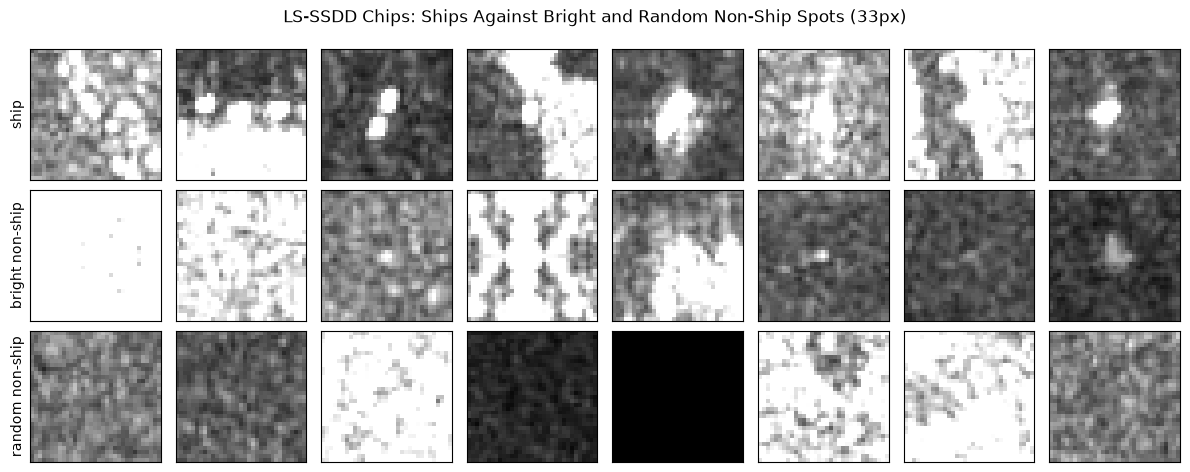

,bright non-ship,random non-ship,ship,total
train,1818,1819,3637,7274
test,1189,1189,2378,4756


In [9]:
SSDD, HALF = RAW / "ls_ssdd", CHIP // 2


def ssdd_chips(split, seed=SEED):
    """ship chips, plus as many non-ship chips (half bright spots, half random) from one ls-ssdd split."""
    rng = np.random.default_rng(seed)
    ships, bright, rand = [], [], []
    for tile in (SSDD / f"{split}.txt").read_text().split():
        # the three bands are identical, so keep one; pad so chips at the edge stay full size
        img = imread(SSDD / f"JPEGImages_sub_{split}" / f"JPEGImages_sub_{split}" / f"{tile}.jpg")[..., 0]
        padded = np.pad(img, HALF, mode="reflect")
        cut = lambda r, c: padded[r:r + CHIP, c:c + CHIP]  # the chip centered on row r, column c of the tile
        near_ship = np.zeros(img.shape, bool)  # each ship plus half a chip around it, so no non-ship chip shows part of a ship
        for o in ET.parse(SSDD / "Annotations_sub" / "Annotations_sub" / f"{tile}.xml").getroot().iter("object"):
            x0, y0, x1, y1 = (int(float(o.find(f"bndbox/{k}").text)) for k in ("xmin", "ymin", "xmax", "ymax"))
            ships.append(cut((y0 + y1) // 2, (x0 + x1) // 2))
            near_ship[max(y0 - HALF, 0):y1 + HALF, max(x0 - HALF, 0):x1 + HALF] = True
        # the two brightest spots away from ships, at least a chip apart, and one random spot away from ships
        bright += [cut(r, c) for r, c in peak_local_max(np.where(near_ship, 0, img), min_distance=CHIP, num_peaks=2, exclude_border=False)]
        rand.append(cut(*np.argwhere(~near_ship)[rng.integers((~near_ship).sum())]))
    n = len(ships)  # as many non-ships as ships, half of each kind
    others = [bright[i] for i in rng.choice(len(bright), n // 2, replace=False)] + [rand[i] for i in rng.choice(len(rand), n - n // 2, replace=False)]
    kind = np.array(["ship"] * n + ["bright non-ship"] * (n // 2) + ["random non-ship"] * (n - n // 2))
    return (np.stack(ships + others)[:, None] / 255).astype("float32"), (kind == "ship").astype(int), kind


ssdd = {split: ssdd_chips(split) for split in ("train", "test")}

# a few chips of each kind, from the training split
X_show, _, kind_show = ssdd["train"]
fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
for row, k in zip(axes, ["ship", "bright non-ship", "random non-ship"]):
    for ax, i in zip(row, np.random.default_rng(SEED).choice(np.flatnonzero(kind_show == k), 8, replace=False)):
        ax.imshow(X_show[i, 0], cmap="gray", vmin=0, vmax=0.5)
        ax.set_xticks([]), ax.set_yticks([])
    row[0].set_ylabel(k, fontsize=10)
fig.suptitle("LS-SSDD Chips: Ships Against Bright and Random Non-Ship Spots (33px)")
plt.tight_layout()
plt.show()
pd.DataFrame({split: pd.Series(kind).value_counts() for split, (_, _, kind) in ssdd.items()}).T.assign(total=lambda d: d.sum(axis=1))

That gave me 12,030 chips, with 7,274 for training and 4,756 for testing. Quite a few ships in the sample above sat close enough to the coast to remind me of the moored dredges on the Madeira. A few bright spots in the background class looked like possible boats too, though it’s hard to tell from those few pixels.

The ship dataset only has VV, so I compared the pretrained network with the same network trained from scratch using just the VV band from the river images. I also applied the ship model directly to the river images before training it further, just to see what it already recognized. Since the ship images use 8 bits for brightness and my images use dB, I standardized each dataset using its own training mean and standard deviation. I repeated the comparison for all three sets of seeds and trained a new ship network for each seed.

In [10]:
def standardize(X, ref):
    # each dataset goes on a common scale using its own pixel mean and spread
    return ((X - ref.mean()) / ref.std()).astype("float32")


ssdd_X = {split: standardize(X, ssdd["train"][0]) for split, (X, _, _) in ssdd.items()}
madeira_vv = standardize(train_chips[:, [0]], train_chips[:, [0]])  # vv on the candidate's own date, the one band both share
scratch, pre = "CNN, VV only, from scratch", "CNN, VV only, pretrained on LS-SSDD"

for seeds in SEED_SETS:
    # pretrain one network per seed on the ls-ssdd training chips
    pretrained = {s: train_net(new_net(1, s), ssdd_X["train"], ssdd["train"][1], s, epochs=10).state_dict() for s in seeds}
    if seeds == SEED_SETS[0]:  # first check: does it learn ships at all, on ls-ssdd tiles it never saw?
        ship_prob = np.mean([predict(new_net(1, s, pretrained[s]), ssdd_X["test"]) for s in seeds], axis=0)
        y_test_ssdd, kind_test = ssdd["test"][1], ssdd["test"][2]
        print(f"LS-SSDD test: ROC AUC {roc_auc_score(y_test_ssdd, ship_prob):.3f}, accuracy {accuracy_score(y_test_ssdd, ship_prob >= 0.5):.3f}")
        print(pd.Series({k: (ship_prob[kind_test == k] >= 0.5).mean() for k in np.unique(kind_test)}, name="share called ship").round(3).to_string())
    probs = {"CNN, LS-SSDD ships only (no fine-tuning)": np.mean([predict(new_net(1, s, pretrained[s]), madeira_vv) for s in seeds], axis=0),
             scratch: cnn_oof(madeira_vv, seeds), pre: cnn_oof(madeira_vv, seeds, start=pretrained.get)}
    for n in (scratch, pre):
        probs[f"{n} + logistic regression"] = (probs[n] + oof["Logistic regression"]) / 2
    add_runs(probs, seeds)

pre_names = ["CNN, LS-SSDD ships only (no fine-tuning)", scratch, pre, f"{scratch} + logistic regression", f"{pre} + logistic regression"]
display(show(["Logistic regression", "Merge only (no model)", "CNN, one date (VV, VH)"] + pre_names, COLS + ["F1 fold 2"]))
# pretrained minus from scratch, within each seed set
r, m = pd.DataFrame(runs).T.astype(float), ["F1", "ROC AUC", "PR AUC (false alarms)"]
display(pd.concat({f"pretrained minus scratch{a}": r.loc[pre + a, m] - r.loc[scratch + a, m] for a in ["", " + logistic regression"]}).round(2))
seed_spread(pre_names)

LS-SSDD test: ROC AUC 0.980, accuracy 0.921
bright non-ship    0.088
random non-ship    0.014
ship               0.893


,precision,recall,F1,F1 fold spread,ROC AUC,PR AUC (false alarms),F1 fold 2
Logistic regression,0.85,0.86,0.85,0.12,0.93,0.62,0.65
Merge only (no model),0.72,0.90,0.80,0.04,NaN,NaN,0.73
"CNN, one date (VV, VH)",0.85,0.84,0.85,0.16,0.90,0.67,0.57
"CNN, LS-SSDD ships only (no fine-tuning)",0.80,0.68,0.73,0.12,0.72,0.44,0.53
"CNN, VV only, from scratch",0.79,0.69,0.74,0.38,0.72,0.19,0.00
"CNN, VV only, pretrained on LS-SSDD",0.82,0.69,0.75,0.32,0.79,0.36,0.12
"CNN, VV only, from scratch + logistic regression",0.78,0.82,0.80,0.21,0.88,0.44,0.43
"CNN, VV only, pretrained on LS-SSDD + logistic regression",0.82,0.83,0.82,0.19,0.91,0.55,0.48


F1  ROC AUC  \
pretrained minus scratch                       0-4    0.01     0.07   
                                               10-14  0.03     0.03   
                                               20-24  0.03     0.08   
pretrained minus scratch + logistic regression 0-4    0.02     0.03   
                                               10-14  0.02     0.00   
                                               20-24  0.04     0.02   

                                                      PR AUC (false alarms)  
pretrained minus scratch                       0-4                     0.16  
                                               10-14                   0.03  
                                               20-24                   0.23  
pretrained minus scratch + logistic regression 0-4                     0.11  
                                               10-14                  -0.00  
                                               20-24                   0.12

F1       ROC AUC        \
                                                     min   max     min   max   
CNN, LS-SSDD ships only (no fine-tuning)            0.73  0.76    0.71  0.73   
CNN, VV only, from scratch                          0.74  0.76    0.72  0.74   
CNN, VV only, pretrained on LS-SSDD                 0.75  0.78    0.78  0.81   
CNN, VV only, from scratch + logistic regression    0.80  0.82    0.88  0.90   
CNN, VV only, pretrained on LS-SSDD + logistic ...  0.82  0.85    0.90  0.92   

                                                   F1 fold 2        
                                                         min   max  
CNN, LS-SSDD ships only (no fine-tuning)                0.53  0.60  
CNN, VV only, from scratch                              0.00  0.12  
CNN, VV only, pretrained on LS-SSDD                     0.12  0.12  
CNN, VV only, from scratch + logistic regression        0.43  0.54  
CNN, VV only, pretrained on LS-SSDD + logistic ...      0.48  0.58

On ship images from tiles set aside for testing, the network got 92% of the chips right at a cutoff of 0.5 (ROC AUC 0.98). When I gave it Madeira images for the first time, it ranked dredges about as well as a network trained from scratch on my VV images. Across three sets of seeds the ship model’s ROC AUC ranged from 0.71 to 0.73, compared with 0.72 to 0.74 for the network trained on the river. It also did better on fold 2, where most of the dredges stayed moored together.

Training the ship model further on river images improved F1 by 0.01 to 0.03 and ROC AUC by 0.03 to 0.08 over starting from scratch with VV. Even then, its best ROC AUC was 0.81, while the CNN trained on both river bands reached 0.89 to 0.92. I only tried one set of pretraining settings and had to account for different brightness scales. I’d be interested in trying ship images with both bands or giving the river model the ship score as another feature.

For the final test, I trained logistic regression and the CNN using both bands from one date on all 225 training candidates. I then scored the 67 candidates from the 34 test sites. Although all 292 candidates appeared in my feature summaries in notebook 02, I chose the models and their settings using the training sites. I resampled those 34 sites 2,000 times, using the same draws for every approach to get 95% intervals for both F1 and the differences between models.

For the comparison with the paper, I scored all 204 dredge labels using predictions from models that hadn’t trained on their sites.

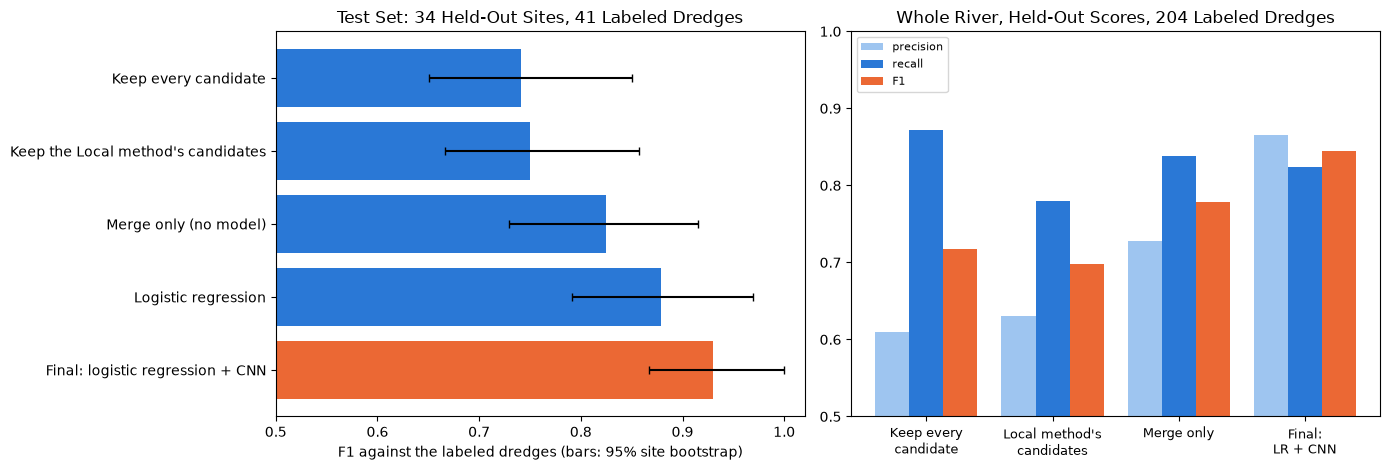

,TP,FP,FN,precision,recall,F1,"F1, 95% interval"
Keep every candidate,40.0,27.0,1.0,0.60,0.98,0.74,0.65 to 0.85
Keep the Local method's candidates,39.0,24.0,2.0,0.62,0.95,0.75,0.67 to 0.86
Merge only (no model),40.0,16.0,1.0,0.71,0.98,0.82,0.73 to 0.92
Logistic regression,40.0,10.0,1.0,0.80,0.98,0.88,0.79 to 0.97
Final: logistic regression + CNN,40.0,5.0,1.0,0.89,0.98,0.93,0.87 to 1.00


,F1 gain,95% interval,share of draws above 0
Final minus merge only,0.1,0.05 to 0.20,1.0
Final minus logistic regression,0.05,0.01 to 0.12,0.984
Final minus Local method,0.18,0.10 to 0.26,1.0


,TP,FP,FN,precision,recall,F1
Keep every candidate,178.0,114.0,26.0,0.61,0.87,0.72
Keep the Local method's candidates,159.0,93.0,45.0,0.63,0.78,0.70
Merge only (no model),171.0,64.0,33.0,0.73,0.84,0.78
Final: logistic regression + CNN,168.0,26.0,36.0,0.87,0.82,0.84


In [11]:
# retrain on every training site, then score once on the held-out sites
test_chips = chips[[cands.index.get_loc(i) for i in test.index]]
lr_test = pipeline(LogisticRegression(max_iter=2000), scale=True).fit(X_train, y_train).predict_proba(test[features].astype(float))[:, 1]
# the same five seeds and settings as in cross-validation, now trained on all 225 training chips
cnn_test = np.mean([predict(train_net(new_net(2, s), train_chips[:, [0, 1]], y_train, s), test_chips[:, [0, 1]]) for s in range(5)], axis=0)
final_test = (lr_test + cnn_test) / 2

approaches = {
    "Keep every candidate": test,
    "Keep the Local method's candidates": test[test["source"] != "Global only"],
    "Merge only (no model)": detect(test, test["vv_peak"].values, -np.inf, MERGE),
    "Logistic regression": detect(test, lr_test, 0.5, MERGE),
    "Final: logistic regression + CNN": detect(test, final_test, 0.5, MERGE),
}
test_results = pd.DataFrame({name: score(kept, truth(test)) for name, kept in approaches.items()}).T

# resample the test sites with replacement; every approach uses the same draws, so the differences are paired
sites = test["site"].unique()
per_site = {name: pd.DataFrame({s: score(kept[kept["site"] == s], truth(test[test["site"] == s])) for s in sites}).T[["TP", "FP", "FN"]]
            for name, kept in approaches.items()}
rng = np.random.default_rng(SEED)
draws = [rng.choice(sites, len(sites), replace=True) for _ in range(2000)]
boot = pd.DataFrame({name: [prf(*c.loc[d].sum())["F1"] for d in draws] for name, c in per_site.items()})
interval = lambda v: f"{v.quantile(0.025):.2f} to {v.quantile(0.975):.2f}"
test_results["F1, 95% interval"] = [interval(boot[n]) for n in test_results.index]
final = boot["Final: logistic regression + CNN"]
gains = pd.DataFrame({f"Final minus {n}": {"F1 gain": round((final - boot[b]).median(), 2), "95% interval": interval(final - boot[b]),
                                           "share of draws above 0": round(((final - boot[b]) > 0).mean(), 3)}
                      for n, b in [("merge only", "Merge only (no model)"), ("logistic regression", "Logistic regression"),
                                   ("Local method", "Keep the Local method's candidates")]}).T

# whole river: held-out scores everywhere (out-of-fold for training sites, the final model for test sites)
river_scores = pd.Series(np.nan, index=cands.index)
river_scores[train.index] = oof["CNN, one date (VV, VH) + logistic regression"]
river_scores[test.index] = final_test
river = pd.DataFrame({
    "Keep every candidate": score(cands, labels),
    "Keep the Local method's candidates": score(cands[cands["source"] != "Global only"], labels),
    "Merge only (no model)": score(detect(cands, cands["vv_peak"].values, -np.inf, MERGE), labels),
    "Final: logistic regression + CNN": score(detect(cands, river_scores.values, 0.5, MERGE), labels),
}).T

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
names = test_results.index[::-1]
err = [[test_results.at[n, "F1"] - boot[n].quantile(0.025) for n in names], [boot[n].quantile(0.975) - test_results.at[n, "F1"] for n in names]]
axes[0].barh(names, test_results.loc[names, "F1"], xerr=err, color=[ORANGE if n.startswith("Final") else BLUE for n in names], capsize=3)
axes[0].set(xlim=(0.5, 1.02), xlabel="F1 against the labeled dredges (bars: 95% site bootstrap)", title="Test Set: 34 Held-Out Sites, 41 Labeled Dredges")
x = np.arange(len(river))
for k, (m, color) in enumerate(zip(["precision", "recall", "F1"], ["#9ec5f0", BLUE, ORANGE])):
    axes[1].bar(x + (k - 1) * 0.27, river[m], width=0.27, color=color, label=m)
axes[1].set_xticks(x, ["Keep every\ncandidate", "Local method's\ncandidates", "Merge only", "Final:\nLR + CNN"], fontsize=9)
axes[1].set(ylim=(0.5, 1), title="Whole River, Held-Out Scores, 204 Labeled Dredges")
axes[1].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "03_final_test.png", dpi=150, bbox_inches="tight")
plt.show()

display(test_results.round(2), gains)
river.round(2)

On the test sites I found 40 of the 41 labeled dredges just by keeping every candidate. My final model also found 40, but it left five false alarms to check instead of 27. That gave it a precision of 0.89, recall of 0.98 and F1 of 0.93 (95% interval 0.87 to 1.00). It beat merging and the Local detector in all 2,000 bootstrap draws, and logistic regression alone in about 98% of them.

Both big dredge fields were in training, which probably explains why the test F1 was higher than the 0.87 to 0.88 I saw during cross validation. I’d want to try another crowded stretch like site 0 before expecting a score of 0.93 there.

Across the whole river the final model found 168 of 204 labeled dredges with 26 false positives (precision 0.87, recall 0.82). Its F1 was 0.84, compared with 0.70 for the Local detector here and 0.68 in the paper. For 26 of the 36 misses, the detectors never produced a candidate within 30m of the label, which capped recall at 0.87 before I trained anything.